# Track 1 — Ablations: Step-Size Control, Additive Penalty, Validation-Based $\lambda$, and Learned Weights

This notebook separates the effects entangled by the convex objective and tests three additional training choices. All primary ablations use the same data-generating process, model family, and evaluation metrics as the preceding Track 1 notebooks.

| Part | Question | Why it is needed |
|---|---|---|
| **A** | Is the gain of end-to-end training at small $\lambda$ caused by the calibration penalty, or by the fact that $\lambda$ also shrinks the step size on the proper loss? | Rules out (or quantifies) a confound behind the "implicit regulariser" claim (RQ1, Q1.10). |
| **B** | Additive-penalty form $\widehat{\mathcal E} + \beta\,\widehat{\mathcal C}_{\text{soft}}$ at a fixed learning rate. | Listed in the plan (§1.4). Because the step size on $\widehat{\mathcal E}$ never changes, this form isolates the penalty's own effect. |
| **C** | Choosing $\lambda$ on a held-out validation set instead of on the test-set $\text{MSE}_\eta$, compared against validation-based early stopping of plain CE. | Every "best $\lambda$" in notebooks 02–06 was read off the ground-truth $\text{MSE}_\eta$, which is an oracle a practitioner does not have. |
| **D** | Learning the loss weights jointly with $\theta$ (homoscedastic uncertainty weighting, Kendall et al. 2018). | Listed as a weight scheme in the chapter skeleton and as an open question in the plan. |

## 0. Configuration

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

# ---- run control ----
SMOKE_TEST = False          # True: 3 seeds, 5,000 test points -- a quick functional check only
FORCE_RERUN = False         # False: load cached CSVs from RESULTS_DIR if they exist
USE_DRIVE = False           # True: mount Google Drive so results survive a Colab runtime reset
RESULTS_DIR = "Track1_07_Results"

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/Colab Notebooks/Thesis/Working Code/Track 1/Track1_07_Results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- experiment constants (identical to notebooks 04-06) ----
N_TRAIN, TEST_SEED = 100, 999
N_TEST = 5_000 if SMOKE_TEST else 50_000
SEED_LIST = list(range(1, (3 if SMOKE_TEST else 30) + 1))
CAPACITIES = [10, 100, 1000]
EPOCHS, LR = 1200, 0.5
INIT_SCALE = np.sqrt(0.01)
SOFT_B, SOFT_H, EVAL_B = 15, 0.08, 10
BASE_LOSS = "ce"

# ---- part-specific grids (see flagged choices above) ----
LAMBDAS_A = [0.05, 0.1, 0.5]
BETAS_B = [0.0, 0.5, 1.0, 2.0, 9.0, 19.0]
LAMBDAS_C = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
VAL_CRITERION = "brier"     # "brier" or "ce"
S_CLIP = (-8.0, 8.0)

PALETTE_CAPACITY = {10: "#264653", 100: "#2a9d8f", 1000: "#e76f51"}
plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    # "font.family": "serif",
    # "font.serif": ["Computer Modern Roman", "CMU Serif"],
    # "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    # "savefig.bbox": "tight",
    # "savefig.pad_inches": 0.05,
    "savefig.format": "pdf"
})
print(f"SMOKE_TEST={SMOKE_TEST}: {len(SEED_LIST)} seeds, n_test={N_TEST}, results -> {RESULTS_DIR}")

SMOKE_TEST=False: 30 seeds, n_test=50000, results -> Track1_07_Results


## 1. Core utilities and the equivalence check against notebook 06

The DGP, Legendre design matrix, initialisation and metrics are copied from notebooks 00–06. Training is re-implemented with analytic gradients:

- **Proper loss.** For CE, $\partial \widehat{E}/\partial z_i = (p_i - y_i)/n$. For Brier, $\partial \widehat{E}/\partial z_i = 2(p_i-y_i)\,p_i(1-p_i)/n$.
- **Soft-ECE penalty (weights $w_{ib}$ treated as constants).**
$$\frac{\partial \widehat{C}_{\text{soft}}}{\partial p_i} = \sum_b \frac{M_b}{n}\,2(\bar p_b - \bar y_b)\,\frac{w_{ib}}{M_b + \varepsilon}, \qquad M_b = \sum_i w_{ib},$$
  followed by the chain rule through $p_i = \sigma(z_i)$.

In [2]:
def true_eta(x):
    x = np.asarray(x, dtype=np.float64)
    return 0.1 + 0.8 / (1.0 + np.exp(-4.0 * np.sin(np.pi * x)))

def generate_data(n, seed):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-1.0, 1.0, size=n)
    Y = rng.binomial(1, true_eta(X)).astype(np.float64)
    return X, Y

def legendre_design_matrix(x, m):
    x = np.asarray(x, dtype=np.float64)
    Phi = np.empty((x.shape[0], m + 1), dtype=np.float64)
    Phi[:, 0] = 1.0
    if m >= 1:
        Phi[:, 1] = x
    for k in range(2, m + 1):
        Phi[:, k] = ((2 * k - 1) * x * Phi[:, k - 1] - (k - 1) * Phi[:, k - 2]) / k
    return Phi

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def init_theta(m, seed):
    return np.random.default_rng(seed).normal(0.0, INIT_SCALE, size=m + 1)

def split_train_val(X, Y, seed, frac_val=0.2):
    perm = np.random.default_rng(seed).permutation(len(X))
    n_val = int(round(len(X) * frac_val))
    v, t = perm[:n_val], perm[n_val:]
    return X[t], Y[t], X[v], Y[v]

# ---------------- losses and analytic gradients ----------------
def soft_ece_value_and_grad_p(p, y, B=SOFT_B, h=SOFT_H, eps=1e-12):
    """C_soft and dC_soft/dp with straight-through (detached) bin weights, as in notebooks 01-06."""
    n = p.shape[0]
    centers = (np.arange(1, B + 1) - 0.5) / B
    logits = -(p[:, None] - centers[None, :]) ** 2 / (2 * h ** 2)
    logits -= logits.max(axis=1, keepdims=True)
    w = np.exp(logits); w /= w.sum(axis=1, keepdims=True)
    M = w.sum(axis=0)
    pbar = (w * p[:, None]).sum(axis=0) / (M + eps)
    ybar = (w * y[:, None]).sum(axis=0) / (M + eps)
    value = np.sum((M / n) * (ybar - pbar) ** 2)
    grad_p = (w * ((M / n) * 2.0 * (pbar - ybar) / (M + eps))[None, :]).sum(axis=1)
    return value, grad_p

def proper_loss_value_and_grad_z(p, y, kind=BASE_LOSS, eps=1e-12):
    n = p.shape[0]
    if kind == "ce":
        pc = np.clip(p, eps, 1 - eps)
        return np.mean(-y * np.log(pc) - (1 - y) * np.log(1 - pc)), (p - y) / n
    if kind == "brier":
        return np.mean((p - y) ** 2), 2.0 * (p - y) * p * (1 - p) / n
    raise ValueError(kind)

def train(X_tr, Y_tr, m, init_seed, w_C, w_E, lr=LR, epochs=EPOCHS, kind=BASE_LOSS, val=None):
    """
    Full-batch GD on  w_C * C_soft + w_E * E_hat.
      convex form   : w_C = 1 - lam, w_E = lam
      additive form : w_C = beta,    w_E = 1
    val=(X_val, Y_val): also returns the checkpoint with the lowest validation score
    (checked after every update, epochs 0..EPOCHS), for early-stopping-by-checkpoint.
    """
    Phi = legendre_design_matrix(X_tr, m)
    theta = init_theta(m, init_seed)
    if val is not None:
        Phi_v, Y_v = legendre_design_matrix(val[0], m), val[1]
        best = (val_score(sigmoid(Phi_v @ theta), Y_v), 0, theta.copy())
    for epoch in range(1, epochs + 1):
        p = sigmoid(Phi @ theta)
        g_z = np.zeros_like(p)
        if w_E != 0.0:
            g_z += w_E * proper_loss_value_and_grad_z(p, Y_tr, kind)[1]
        if w_C != 0.0:
            g_z += w_C * soft_ece_value_and_grad_p(p, Y_tr)[1] * p * (1 - p)
        theta = theta - lr * (Phi.T @ g_z)
        if val is not None:
            sc = val_score(sigmoid(Phi_v @ theta), Y_v)
            if sc < best[0]:
                best = (sc, epoch, theta.copy())
    if val is None:
        return theta
    return theta, {"best_epoch": best[1], "best_val": best[0], "theta_best": best[2]}

def val_score(p, y):
    if VAL_CRITERION == "brier":
        return np.mean((p - y) ** 2)
    pc = np.clip(p, 1e-12, 1 - 1e-12)
    return np.mean(-y * np.log(pc) - (1 - y) * np.log(1 - pc))

# ---------------- evaluation metrics (identical definitions to notebook 06) ----------------
def top_label_ece(p, y, B=EVAL_B):
    conf = np.maximum(p, 1 - p)
    correct = ((p >= 0.5).astype(np.float64) == y).astype(np.float64)
    edges = np.linspace(0.5, 1.0, B + 1)
    idx = np.clip(np.digitize(conf, edges[1:-1]), 0, B - 1)
    ece = 0.0
    for b in range(B):
        mk = idx == b
        if mk.any():
            ece += mk.mean() * abs(correct[mk].mean() - conf[mk].mean())
    return ece

def brier_cal_ref(p, y, B=EVAL_B, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    edges = np.linspace(0.0, 1.0, B + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, B - 1)
    total, cal = np.mean((p - y) ** 2), 0.0
    for b in range(B):
        mk = idx == b
        if mk.any():
            cal += mk.mean() * (p[mk].mean() - y[mk].mean()) ** 2
    return cal, total - cal

def eval_metrics(p, Y_te, eta_te):
    pc = np.clip(p, 1e-12, 1 - 1e-12)
    cal, ref = brier_cal_ref(p, Y_te)
    return {"test_ce": np.mean(-Y_te * np.log(pc) - (1 - Y_te) * np.log(1 - pc)),
            "brier": np.mean((p - Y_te) ** 2), "ece": top_label_ece(p, Y_te),
            "mse_eta": np.mean((p - eta_te) ** 2), "brier_cal": cal, "brier_ref": ref}

X_te, Y_te = generate_data(N_TEST, TEST_SEED)
eta_te = true_eta(X_te)
print(f"test set: n={len(X_te)}, positive rate={Y_te.mean():.3f}")

test set: n=50000, positive rate=0.501


### Equivalence check against notebook 06 (must pass)

Notebook 06, cell 11 prints, for data seed 1, init seed 10042, $m=100$, $\lambda=0.5$ (CE), on the full test set:

`test_ce = 0.5854648820627176`, `mse_eta = 0.023306753778268144`

This check needs the full $n_{\text{test}}=50{,}000$ test set, so it is skipped when `SMOKE_TEST=True`.

In [3]:
if not SMOKE_TEST:
    X1, Y1 = generate_data(N_TRAIN, 1)
    th = train(X1, Y1, m=100, init_seed=10042, w_C=0.5, w_E=0.5)
    met = eval_metrics(sigmoid(legendre_design_matrix(X_te, 100) @ th), Y_te, eta_te)
    print(f"test_ce = {met['test_ce']!r}\nmse_eta = {met['mse_eta']!r}")
    assert abs(met["test_ce"] - 0.5854648820627176) < 1e-9
    assert abs(met["mse_eta"] - 0.023306753778268144) < 1e-9
    print("OK: NumPy training reproduces notebook 06 (PyTorch autograd) to numerical precision.")
else:
    print("SMOKE_TEST: equivalence check skipped (needs the full test set).")

test_ce = np.float64(0.5854648820627176)
mse_eta = np.float64(0.02330675377826814)
OK: NumPy training reproduces notebook 06 (PyTorch autograd) to numerical precision.


## 2. An identity that explains why Part A is needed

With full-batch gradient descent at learning rate $\eta$, one step on the convex objective is
$$
\theta \leftarrow \theta - \eta\big[(1-\lambda)\nabla\widehat{\mathcal C}_{\text{soft}} + \lambda\nabla\widehat{\mathcal E}\big]
= \theta - (\eta\lambda)\Big[\nabla\widehat{\mathcal E} + \tfrac{1-\lambda}{\lambda}\nabla\widehat{\mathcal C}_{\text{soft}}\Big].
$$
So **the convex form with learning rate $\eta$ is exactly the additive form with $\beta = (1-\lambda)/\lambda$ and learning rate $\eta\lambda$.** Lowering $\lambda$ does two things at once: it strengthens the penalty relative to $\widehat{\mathcal E}$, and it shrinks the effective step size on $\widehat{\mathcal E}$ by a factor of $\lambda$. With a fixed budget of 1,200 epochs and no early stopping, the second effect alone acts like stopping plain CE training early (Berta et al., 2025).

Part A separates the two effects. It compares end-to-end training at $\lambda$ with plain CE trained at learning rate $\eta\lambda$, which is the additive form with $\beta = 0$ at the same step size. The cell below checks the identity numerically.

In [4]:
Xc, Yc = generate_data(N_TRAIN, 1)
lam = 0.1
th_convex = train(Xc, Yc, m=100, init_seed=10001, w_C=1 - lam, w_E=lam, lr=LR)
th_additive = train(Xc, Yc, m=100, init_seed=10001, w_C=(1 - lam) / lam, w_E=1.0, lr=LR * lam)
diff = np.max(np.abs(th_convex - th_additive))
print(f"max |theta_convex(lam=0.1, lr=0.5) - theta_additive(beta=9, lr=0.05)| = {diff:.2e}")
assert diff < 1e-8
print("OK: the two parameterisations follow the same trajectory.")

max |theta_convex(lam=0.1, lr=0.5) - theta_additive(beta=9, lr=0.05)| = 2.22e-16
OK: the two parameterisations follow the same trajectory.


## 3. Part A — step-size-matched control

Every entry below uses a **CE base loss**, $n = 100$ training points, and 1,200 epochs.

| Condition | Objective | Learning rate |
|---|---|---|
| `baseline` | CE only ($\lambda = 1$) | 0.5 |
| `e2e` | $(1-\lambda)\,\widehat{C}_{\text{soft}} + \lambda\,\widehat{E}$ | 0.5 |
| `ctrl` | CE only | $0.5\lambda$ |

`e2e` and `ctrl` use the same step size on $\widehat{E}$ and differ only in whether the penalty is present. The comparison `e2e` vs. `ctrl` is therefore a direct test of the penalty itself.

**Significance.** Paired Wilcoxon signed-rank test over seeds, with Bonferroni correction across $3$ capacities $\times$ $3$ values of $\lambda$ $= 9$ comparisons per metric.

**Share of the gain explained by step size.**
$$\text{share} = \frac{\overline{\text{baseline}} - \overline{\text{ctrl}}}{\overline{\text{baseline}} - \overline{\text{e2e}}}$$
- A share near 1 means the step-size effect explains almost all of the improvement.
- A share near 0 means the penalty is doing the work.

In [5]:
def cached(name, fn):
    path = os.path.join(RESULTS_DIR, name)
    if os.path.exists(path) and not FORCE_RERUN:
        print(f"loaded cached {path}")
        return pd.read_csv(path)
    t0 = time.time()
    df = fn()
    df.to_csv(path, index=False)
    print(f"computed and saved {path} ({time.time() - t0:.0f}s)")
    return df

def run_part_a():
    rec = []
    for m in CAPACITIES:
        Phi_te = legendre_design_matrix(X_te, m)
        for s in SEED_LIST:
            X, Y = generate_data(N_TRAIN, s)
            th = train(X, Y, m, 10000 + s, w_C=0.0, w_E=1.0, lr=LR)
            rec.append({"m": m, "seed": s, "cond": "baseline", "lam": 1.0,
                        **eval_metrics(sigmoid(Phi_te @ th), Y_te, eta_te)})
            for lam in LAMBDAS_A:
                th = train(X, Y, m, 10000 + s, w_C=1 - lam, w_E=lam, lr=LR)
                rec.append({"m": m, "seed": s, "cond": "e2e", "lam": lam,
                            **eval_metrics(sigmoid(Phi_te @ th), Y_te, eta_te)})
                th = train(X, Y, m, 10000 + s, w_C=0.0, w_E=1.0, lr=LR * lam)
                rec.append({"m": m, "seed": s, "cond": "ctrl", "lam": lam,
                            **eval_metrics(sigmoid(Phi_te @ th), Y_te, eta_te)})
        del Phi_te
        print(f"  Part A: m={m} done")
    return pd.DataFrame(rec)

dfA = cached("partA_step_size_control.csv", run_part_a)

  Part A: m=10 done
  Part A: m=100 done
  Part A: m=1000 done
computed and saved Track1_07_Results/partA_step_size_control.csv (194s)


In [6]:
METRICS = ["mse_eta", "ece", "brier", "brier_cal", "brier_ref", "test_ce"]

def fmt(x):
    return f"{x.mean():.4f} ± {x.std(ddof=1):.4f}"

def paired_p(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if len(a) < 6 or np.allclose(a, b):
        return np.nan
    return wilcoxon(a, b).pvalue

def stars(p):
    if np.isnan(p): return "n/a"
    return "**" if p < 0.01 else ("*" if p < 0.05 else "n.s.")

rows, sig = [], []
n_cmp = len(CAPACITIES) * len(LAMBDAS_A)
for m in CAPACITIES:
    base = dfA[(dfA.m == m) & (dfA.cond == "baseline")].sort_values("seed")
    rows.append({"m": m, "condition": "baseline (lr=0.5)", **{k: fmt(base[k]) for k in METRICS}})
    for lam in LAMBDAS_A:
        e = dfA[(dfA.m == m) & (dfA.cond == "e2e") & (dfA.lam == lam)].sort_values("seed")
        c = dfA[(dfA.m == m) & (dfA.cond == "ctrl") & (dfA.lam == lam)].sort_values("seed")
        rows.append({"m": m, "condition": f"e2e lam={lam} (lr=0.5)", **{k: fmt(e[k]) for k in METRICS}})
        rows.append({"m": m, "condition": f"CE ctrl (lr={LR*lam:g})", **{k: fmt(c[k]) for k in METRICS}})
        for k in ["mse_eta", "ece", "brier_cal", "brier_ref"]:
            p = paired_p(e[k].values, c[k].values)
            pb = min(p * n_cmp, 1.0) if not np.isnan(p) else np.nan
            gain_total = base[k].mean() - e[k].mean()
            share = (base[k].mean() - c[k].mean()) / gain_total if abs(gain_total) > 1e-12 else np.nan
            sig.append({"m": m, "lam": lam, "metric": k, "e2e_mean": round(e[k].mean(), 4),
                        "ctrl_mean": round(c[k].mean(), 4), "base_mean": round(base[k].mean(), 4),
                        "e2e_minus_ctrl": round(e[k].mean() - c[k].mean(), 4),
                        "share_explained_by_step_size": round(share, 3),
                        "p_bonf": round(pb, 4) if not np.isnan(pb) else np.nan, "signif": stars(pb)})

table_1e = pd.DataFrame(rows).set_index(["m", "condition"])
table_1e.to_csv(os.path.join(RESULTS_DIR, "table_1e.csv"))
table_1e.to_excel(os.path.join(RESULTS_DIR, "table_1e.xlsx"))
print("Table 1-E: Step-size-matched control, mean ± std over seeds\n")
print(table_1e.to_string())

sig_A = pd.DataFrame(sig)
sig_A.to_csv(os.path.join(RESULTS_DIR, "sig_A.csv"), index=False)
sig_A.to_excel(os.path.join(RESULTS_DIR, "sig_A.xlsx"), index=False)
print("\nPaired Wilcoxon e2e vs. step-matched CE control (Bonferroni x%d):\n" % n_cmp)
print(sig_A.to_string(index=False))

Table 1-E: Step-size-matched control, mean ± std over seeds

                                    mse_eta              ece            brier        brier_cal        brier_ref          test_ce
m    condition                                                                                                                  
10   baseline (lr=0.5)      0.0189 ± 0.0078  0.0694 ± 0.0195  0.1663 ± 0.0077  0.0090 ± 0.0039  0.1573 ± 0.0053  0.5512 ± 0.0424
     e2e lam=0.05 (lr=0.5)  0.0097 ± 0.0054  0.0453 ± 0.0184  0.1574 ± 0.0054  0.0050 ± 0.0037  0.1524 ± 0.0031  0.4963 ± 0.0173
     CE ctrl (lr=0.025)     0.0131 ± 0.0045  0.0644 ± 0.0263  0.1606 ± 0.0044  0.0083 ± 0.0040  0.1523 ± 0.0019  0.5010 ± 0.0112
     e2e lam=0.1 (lr=0.5)   0.0101 ± 0.0054  0.0459 ± 0.0179  0.1577 ± 0.0054  0.0051 ± 0.0038  0.1525 ± 0.0029  0.4981 ± 0.0170
     CE ctrl (lr=0.05)      0.0100 ± 0.0047  0.0447 ± 0.0171  0.1575 ± 0.0047  0.0052 ± 0.0035  0.1523 ± 0.0025  0.4940 ± 0.0123
     e2e lam=0.5 (lr=0.5)   0.0163 ±

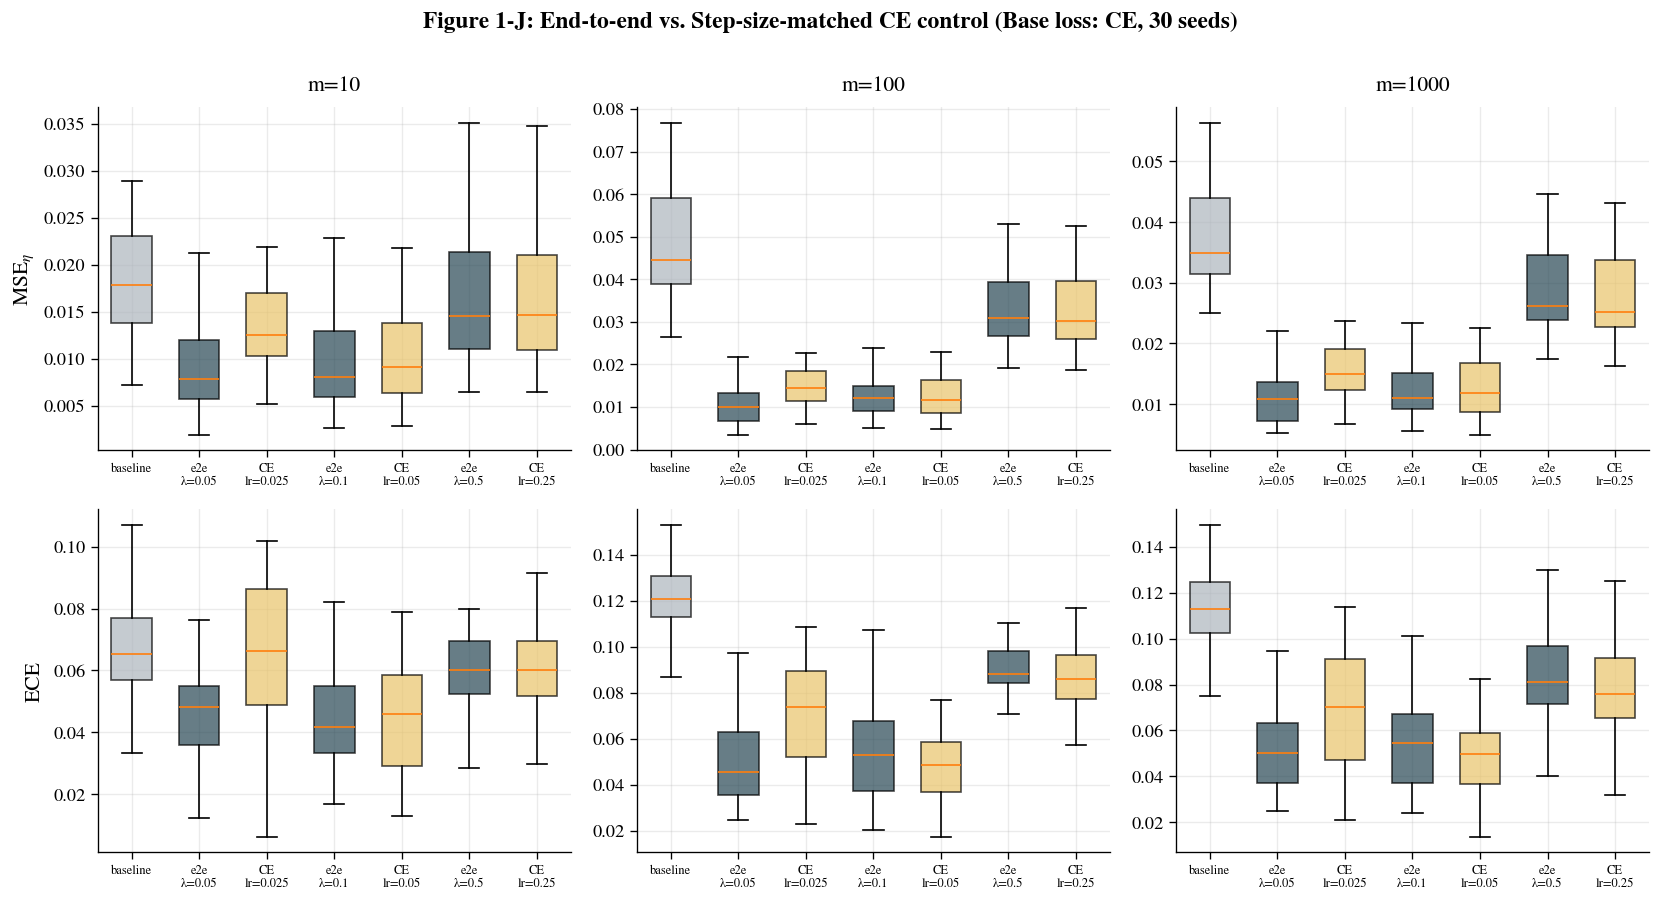

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for col, m in enumerate(CAPACITIES):
    for row, (k, title) in enumerate([("mse_eta", r"MSE$_\eta$"), ("ece", "ECE")]):
        ax = axes[row, col]
        data, labels, colors = [], [], []
        base = dfA[(dfA.m == m) & (dfA.cond == "baseline")][k].values
        data.append(base); labels.append("baseline"); colors.append("#adb5bd")
        for lam in LAMBDAS_A:
            data.append(dfA[(dfA.m == m) & (dfA.cond == "e2e") & (dfA.lam == lam)][k].values)
            labels.append(f"e2e\nλ={lam}"); colors.append("#264653")
            data.append(dfA[(dfA.m == m) & (dfA.cond == "ctrl") & (dfA.lam == lam)][k].values)
            labels.append(f"CE\nlr={LR*lam:g}"); colors.append("#e9c46a")
        bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
        for box, c in zip(bp["boxes"], colors):
            box.set_facecolor(c); box.set_alpha(0.7)
        ax.set_xticks(range(1, len(labels) + 1)); ax.set_xticklabels(labels, fontsize=7.5)
        if row == 0: ax.set_title(f"m={m}", pad=10)
        if col == 0: ax.set_ylabel(title, labelpad=5)

fig.suptitle("Figure 1-J: End-to-end vs. Step-size-matched CE control "
             f"(Base loss: CE, {len(SEED_LIST)} seeds)", y=1.0)
for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()

fig.savefig(os.path.join(RESULTS_DIR, "Figure_1J.pdf"), format="pdf", bbox_inches="tight")
plt.show()

## 4. Part B — additive-penalty form at a fixed learning rate

Objective: $\widehat{\mathcal E} + \beta\,\widehat{\mathcal C}_{\text{soft}}$, learning rate 0.5, 1,200 epochs, all 100 training points.

- $\beta = 0$ is exactly the CE baseline.
- $\beta \in \{0.5, 1, 2\}$ is the plan's grid.
- $\beta \in \{9, 19\}$ is the extension: the penalty-to-loss ratios that correspond to $\lambda = 0.1$ and $\lambda = 0.05$.

Because the step size on $\widehat{\mathcal E}$ is identical in every run, any difference from $\beta = 0$ is caused by the penalty alone.

**Significance.** Each $\beta > 0$ is tested against $\beta = 0$ with a paired Wilcoxon test, Bonferroni-corrected across $3 \times 5 = 15$ comparisons per metric.

In [8]:
def run_part_b():
    rec = []
    for m in CAPACITIES:
        Phi_te = legendre_design_matrix(X_te, m)
        for s in SEED_LIST:
            X, Y = generate_data(N_TRAIN, s)
            for beta in BETAS_B:
                th = train(X, Y, m, 10000 + s, w_C=beta, w_E=1.0, lr=LR)
                p = sigmoid(Phi_te @ th)
                rec.append({"m": m, "seed": s, "beta": beta, "finite": bool(np.all(np.isfinite(th))),
                            **eval_metrics(p, Y_te, eta_te)})
        del Phi_te
        print(f"  Part B: m={m} done")
    return pd.DataFrame(rec)

dfB = cached("partB_additive_penalty.csv", run_part_b)
print(f"non-finite parameter vectors: {int((~dfB.finite).sum())} of {len(dfB)}")

rows, sig = [], []
n_cmp = len(CAPACITIES) * (len(BETAS_B) - 1)
for m in CAPACITIES:
    b0 = dfB[(dfB.m == m) & (dfB.beta == 0.0)].sort_values("seed")
    for beta in BETAS_B:
        d = dfB[(dfB.m == m) & (dfB.beta == beta)].sort_values("seed")
        rows.append({"m": m, "beta": beta, **{k: fmt(d[k]) for k in METRICS}})
        if beta > 0:
            for k in ["mse_eta", "ece", "brier_cal", "brier_ref"]:
                p = paired_p(d[k].values, b0[k].values)
                pb = min(p * n_cmp, 1.0) if not np.isnan(p) else np.nan
                sig.append({"m": m, "beta": beta, "metric": k, "mean": round(d[k].mean(), 4),
                            "beta0_mean": round(b0[k].mean(), 4),
                            "p_bonf": round(pb, 4) if not np.isnan(pb) else np.nan, "signif": stars(pb)})
table_1f = pd.DataFrame(rows).set_index(["m", "beta"])
table_1f.to_csv(os.path.join(RESULTS_DIR, "table_1f.csv"))
table_1f.to_excel(os.path.join(RESULTS_DIR, "table_1f.xlsx"))
print("\nTable 1-F: Additive penalty at lr=0.5, mean ± std over seeds\n")
print(table_1f.to_string())

sig_B = pd.DataFrame(sig)
sig_B.to_csv(os.path.join(RESULTS_DIR, "sig_B.csv"), index=False)
sig_B.to_excel(os.path.join(RESULTS_DIR, "sig_B.xlsx"), index=False)
print(f"\nPaired Wilcoxon beta vs beta=0 (Bonferroni x{n_cmp}):\n")
print(sig_B.to_string(index=False))

  Part B: m=10 done
  Part B: m=100 done
  Part B: m=1000 done
computed and saved Track1_07_Results/partB_additive_penalty.csv (193s)
non-finite parameter vectors: 0 of 540

Table 1-F: Additive penalty at lr=0.5, mean ± std over seeds

                   mse_eta              ece            brier        brier_cal        brier_ref          test_ce
m    beta                                                                                                      
10   0.0   0.0189 ± 0.0078  0.0694 ± 0.0195  0.1663 ± 0.0077  0.0090 ± 0.0039  0.1573 ± 0.0053  0.5512 ± 0.0424
     0.5   0.0189 ± 0.0078  0.0697 ± 0.0196  0.1663 ± 0.0077  0.0090 ± 0.0039  0.1573 ± 0.0053  0.5516 ± 0.0431
     1.0   0.0189 ± 0.0079  0.0695 ± 0.0196  0.1663 ± 0.0078  0.0090 ± 0.0040  0.1573 ± 0.0053  0.5520 ± 0.0437
     2.0   0.0189 ± 0.0079  0.0697 ± 0.0198  0.1663 ± 0.0078  0.0090 ± 0.0040  0.1573 ± 0.0054  0.5527 ± 0.0447
     9.0   0.0192 ± 0.0081  0.0701 ± 0.0213  0.1666 ± 0.0080  0.0091 ± 0.0043  0.1575 ± 0.00

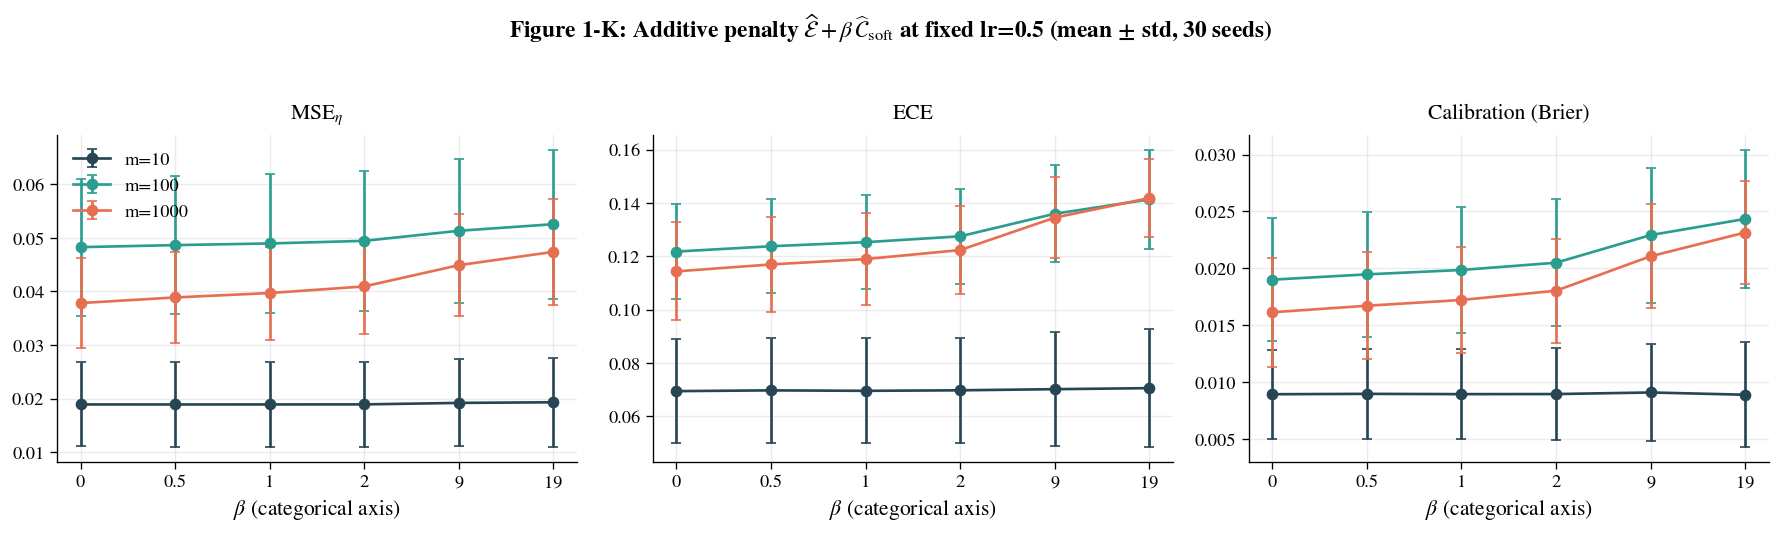

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (k, title) in zip(axes, [("mse_eta", r"MSE$_\eta$"), ("ece", "ECE"), ("brier_cal", "Calibration (Brier)")]):
    for m in CAPACITIES:
        g = dfB[dfB.m == m].groupby("beta")[k]
        mu, sd = g.mean(), g.std(ddof=1)
        xs = np.arange(len(mu))
        ax.errorbar(xs, mu.values, yerr=sd.values, color=PALETTE_CAPACITY[m], marker="o",
                    capsize=3, lw=1.6, label=f"m={m}")
        ax.set_xticks(xs)
        ax.set_xticklabels([f"{b:g}" for b in mu.index])
    ax.set_xlabel(r"$\beta$ (categorical axis)", labelpad=4)
    # ax.set_ylabel("Value", labelpad=5)
    ax.set_title(title, pad=10)
axes[0].legend(frameon=False, loc="best")
fig.suptitle(r"Figure 1-K: Additive penalty $\widehat{\mathcal{E}}+\beta\,\widehat{\mathcal{C}}_{\mathrm{soft}}$ at fixed lr=0.5 "
             f"(mean ± std, {len(SEED_LIST)} seeds)", y=1.03)

for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "Figure_1K.pdf"), format="pdf", bbox_inches="tight")
plt.show()

## 5. Part C — validation-based selection vs. validation-based early stopping

For each seed, the 100 training points are split 80/20 using split seed $20000+s$, the same convention as notebook 04.

**Pipeline 1: end-to-end with $\lambda$ chosen on validation data (`e2e-val`)**
1. Train the convex objective on the 80 points for every $\lambda$ in the grid.
2. Pick $\hat\lambda$ with the lowest validation score.
3. Report the 80-point model with $\hat\lambda$.
4. Also report a re-fit on all 100 points with the same $\hat\lambda$.

**Pipeline 2: plain CE with validation early stopping (`CE-ES`)**
1. Train plain CE on the 80 points (this is the $\lambda = 1$ run).
2. Keep the checkpoint $\hat t$ with the lowest validation score.
3. Report that checkpoint.
4. Also report a re-fit on all 100 points for $\hat t$ epochs.

**Oracle references:**
- The 80-point model at the fixed $\lambda = 0.1$ used in notebooks 03 and 06.
- The 80-point model at $\lambda = 1$ trained for the full 1,200 epochs.

**Significance.** `e2e-val` vs. `CE-ES` is tested with a paired Wilcoxon test, for the 80-point and re-fit versions separately. Bonferroni correction is across $3$ capacities $\times$ $2$ versions $= 6$ comparisons per metric.

Keep in mind that 20 validation points make both selection rules noisy. The spread of $\hat\lambda$ and $\hat t$ across seeds is a result in its own right.

In [15]:
def run_part_c():
    rec, sel = [], []
    for m in CAPACITIES:
        Phi_te = legendre_design_matrix(X_te, m)
        for s in SEED_LIST:
            X, Y = generate_data(N_TRAIN, s)
            Xtr, Ytr, Xv, Yv = split_train_val(X, Y, seed=20000 + s)
            Phi_v = legendre_design_matrix(Xv, m)
            scores, thetas = {}, {}
            es_info = None
            for lam in LAMBDAS_C:
                if lam == 1.0:
                    th, es_info = train(Xtr, Ytr, m, 10000 + s, w_C=0.0, w_E=1.0, val=(Xv, Yv))
                else:
                    th = train(Xtr, Ytr, m, 10000 + s, w_C=1 - lam, w_E=lam)
                thetas[lam] = th
                scores[lam] = val_score(sigmoid(Phi_v @ th), Yv)
            lam_hat = min(scores, key=scores.get)
            t_hat = es_info["best_epoch"]
            th_e2e_refit = train(X, Y, m, 10000 + s, w_C=1 - lam_hat, w_E=lam_hat)
            th_es_refit = (train(X, Y, m, 10000 + s, w_C=0.0, w_E=1.0, epochs=t_hat)
                           if t_hat > 0 else init_theta(m, 10000 + s))
            models = {"e2e-val (80)": thetas[lam_hat], "CE-ES (80)": es_info["theta_best"],
                      "e2e-val (refit 100)": th_e2e_refit, "CE-ES (refit 100)": th_es_refit,
                      "e2e lam=0.1 (80, oracle-chosen)": thetas[0.1],
                      "CE full 1200 ep (80)": thetas[1.0]}
            for name, th in models.items():
                rec.append({"m": m, "seed": s, "pipeline": name,
                            **eval_metrics(sigmoid(Phi_te @ th), Y_te, eta_te)})
            sel.append({"m": m, "seed": s, "lam_hat": lam_hat, "t_hat": t_hat})
        del Phi_te
        print(f"  Part C: m={m} done")
    return pd.DataFrame(rec), pd.DataFrame(sel)

pC, pS = os.path.join(RESULTS_DIR, "partC_validation.csv"), os.path.join(RESULTS_DIR, "partC_selected.csv")
if os.path.exists(pC) and os.path.exists(pS) and not FORCE_RERUN:
    dfC, dfS = pd.read_csv(pC), pd.read_csv(pS); print("loaded cached Part C")
else:
    t0 = time.time(); dfC, dfS = run_part_c()
    dfC.to_csv(pC, index=False); dfS.to_csv(pS, index=False)
    print(f"computed Part C ({time.time() - t0:.0f}s)")

  Part C: m=10 done
  Part C: m=100 done
  Part C: m=1000 done
computed Part C (231s)


In [16]:
order = ["e2e-val (80)", "CE-ES (80)", "e2e-val (refit 100)", "CE-ES (refit 100)",
         "e2e lam=0.1 (80, oracle-chosen)", "CE full 1200 ep (80)"]
rows = []
for m in CAPACITIES:
    for name in order:
        d = dfC[(dfC.m == m) & (dfC.pipeline == name)]
        rows.append({"m": m, "pipeline": name, **{k: fmt(d[k]) for k in METRICS}})
table_1g = pd.DataFrame(rows).set_index(["m", "pipeline"])
table_1g.to_csv(os.path.join(RESULTS_DIR, "table_1g.csv"))
table_1g.to_excel(os.path.join(RESULTS_DIR, "table_1g.xlsx"))
print("Table 1-G: Validation-based pipelines, mean ± std over seeds\n")
print(table_1g.to_string())

sig = []
for m in CAPACITIES:
    for a, b in [("e2e-val (80)", "CE-ES (80)"), ("e2e-val (refit 100)", "CE-ES (refit 100)")]:
        A = dfC[(dfC.m == m) & (dfC.pipeline == a)].sort_values("seed")
        B = dfC[(dfC.m == m) & (dfC.pipeline == b)].sort_values("seed")
        for k in ["mse_eta", "ece", "brier"]:
            p = paired_p(A[k].values, B[k].values)
            pb = min(p * 6, 1.0) if not np.isnan(p) else np.nan
            sig.append({"m": m, "comparison": f"{a} vs {b}", "metric": k,
                        "mean_A": round(A[k].mean(), 4), "mean_B": round(B[k].mean(), 4),
                        "p_bonf": round(pb, 4) if not np.isnan(pb) else np.nan, "signif": stars(pb)})
sig_C = pd.DataFrame(sig)
sig_C.to_csv(os.path.join(RESULTS_DIR, "sig_C.csv"), index=False)
sig_C.to_excel(os.path.join(RESULTS_DIR, "sig_C.xlsx"), index=False)
print("\nPaired Wilcoxon (Bonferroni x6):\n")
print(sig_C.to_string(index=False))

print("\nSelected lambda counts per capacity (validation " + VAL_CRITERION + "):")
print(dfS.pivot_table(index="m", columns="lam_hat", values="seed", aggfunc="count", fill_value=0).to_string())
print("\nSelected early-stopping epoch t_hat per capacity:")
print(dfS.groupby("m")["t_hat"].describe()[["mean", "std", "min", "50%", "max"]].round(1).to_string())

Table 1-G: Validation-based pipelines, mean ± std over seeds

                                              mse_eta              ece            brier        brier_cal        brier_ref          test_ce
m    pipeline                                                                                                                             
10   e2e-val (80)                     0.0142 ± 0.0084  0.0587 ± 0.0227  0.1618 ± 0.0082  0.0075 ± 0.0052  0.1543 ± 0.0046  0.5195 ± 0.0383
     CE-ES (80)                       0.0210 ± 0.0134  0.0757 ± 0.0469  0.1683 ± 0.0132  0.0129 ± 0.0111  0.1554 ± 0.0047  0.5338 ± 0.0408
     e2e-val (refit 100)              0.0131 ± 0.0091  0.0529 ± 0.0248  0.1607 ± 0.0089  0.0062 ± 0.0047  0.1545 ± 0.0053  0.5154 ± 0.0405
     CE-ES (refit 100)                0.0200 ± 0.0154  0.0755 ± 0.0512  0.1674 ± 0.0152  0.0122 ± 0.0134  0.1552 ± 0.0055  0.5312 ± 0.0455
     e2e lam=0.1 (80, oracle-chosen)  0.0122 ± 0.0058  0.0535 ± 0.0198  0.1598 ± 0.0058  0.0066 ± 0.0046

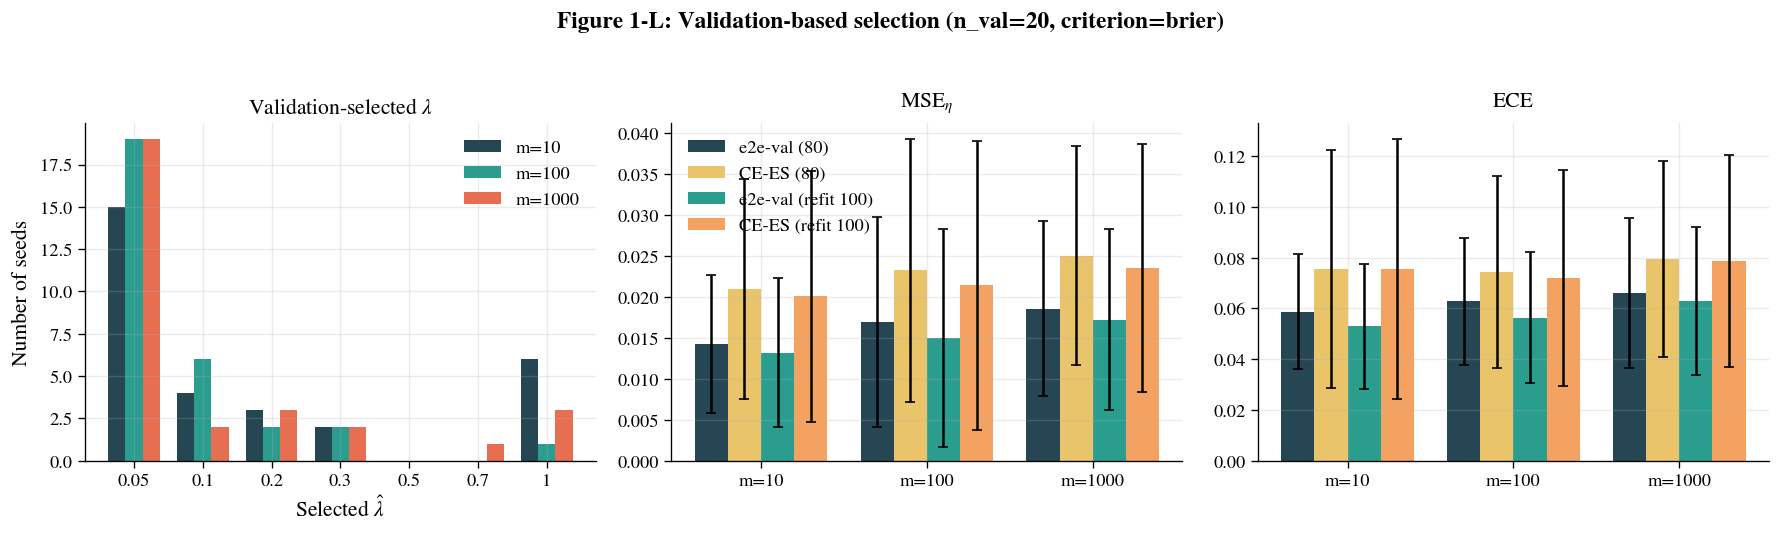

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ax = axes[0]
width = 0.25
for i, m in enumerate(CAPACITIES):
    counts = dfS[dfS.m == m]["lam_hat"].value_counts().reindex(LAMBDAS_C, fill_value=0)
    ax.bar(np.arange(len(LAMBDAS_C)) + (i - 1) * width, counts.values, width,
           color=PALETTE_CAPACITY[m], label=f"m={m}")
ax.set_xticks(np.arange(len(LAMBDAS_C))); ax.set_xticklabels([f"{l:g}" for l in LAMBDAS_C])
ax.set_xlabel(r"Selected $\hat\lambda$", labelpad=4)
ax.set_ylabel("Number of seeds", labelpad=5)
ax.set_title(r"Validation-selected $\lambda$")
ax.legend(frameon=False, loc="best")

show = ["e2e-val (80)", "CE-ES (80)", "e2e-val (refit 100)", "CE-ES (refit 100)"]
cols = ["#264653", "#e9c46a", "#2a9d8f", "#f4a261"]
for ax, (k, title) in zip(axes[1:], [("mse_eta", r"MSE$_\eta$"), ("ece", "ECE")]):
    for j, name in enumerate(show):
        g = dfC[dfC.pipeline == name].groupby("m")[k]
        ax.bar(np.arange(3) + (j - 1.5) * 0.2, g.mean().values, 0.2, yerr=g.std(ddof=1).values,
               capsize=3, color=cols[j], label=name)
    ax.set_xticks(range(3))
    ax.set_xticklabels([f"m={m}" for m in CAPACITIES])
    ax.set_title(title, pad=10)
axes[1].legend(frameon=False, loc="upper left")
fig.suptitle(f"Figure 1-L: Validation-based selection (n_val=20, criterion={VAL_CRITERION})", y=1.03)

for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "Figure_1L.pdf"), format="pdf", bbox_inches="tight")
plt.show()

## 6. Part D — learned loss weights (homoscedastic uncertainty weighting)

With $s_C = \log\sigma_C^2$ and $s_E = \log\sigma_E^2$:
$$
\mathcal{L}_{\text{UW}}(\theta, s) = \tfrac12 e^{-s_C}\,\widehat{\mathcal C}_{\text{soft}}(\theta) + \tfrac12 e^{-s_E}\,\widehat{\mathcal E}(\theta) + \tfrac12 (s_C + s_E).
$$

**What the weights converge to.** For fixed $\theta$, the optimal log-variance is $s_i^\star = \log L_i$. The effective weight on each loss then becomes $\tfrac{1}{2L_i}$. The alternative parameterisation $e^{-s}L + \tfrac12 s$ gives the same effective weight, so this conclusion does not depend on which of the two forms is used.

**Why this scheme may behave badly here.** The training calibration error $\widehat{\mathcal C}_{\text{soft}}$ is typically $10^{-3}$–$10^{-2}$, while CE is about $0.5$. The scheme will therefore tend to put a very large weight on the penalty. Clipping $s$ to $[-8, 8]$ keeps this bounded; the notebook records how often the clip is reached.

**Implied convex weight.** Each run records
$$\lambda_{\text{eff}} = \frac{w_E}{w_C + w_E}$$
over training, so the result can be compared with the fixed-$\lambda$ grid.

**Comparisons.** UW is compared with `baseline` and with `e2e` at $\lambda = 0.1$ from Part A (same seeds, same initialisation, $n = 100$). Paired Wilcoxon tests are Bonferroni-corrected across $3 \times 2 = 6$ comparisons per metric.

In [18]:
def train_uw(X_tr, Y_tr, m, init_seed, lr=LR, lr_s=LR, epochs=EPOCHS, log_every=10):
    Phi = legendre_design_matrix(X_tr, m)
    theta = init_theta(m, init_seed)
    s = np.zeros(2)                                  # [s_C, s_E]
    traj, clip_hits = [], 0
    for epoch in range(1, epochs + 1):
        p = sigmoid(Phi @ theta)
        C_val, dC_dp = soft_ece_value_and_grad_p(p, Y_tr)
        E_val, dE_dz = proper_loss_value_and_grad_z(p, Y_tr)
        w_C, w_E = 0.5 * np.exp(-s[0]), 0.5 * np.exp(-s[1])
        g_z = w_C * dC_dp * p * (1 - p) + w_E * dE_dz
        theta = theta - lr * (Phi.T @ g_z)
        g_s = np.array([-w_C * C_val + 0.5, -w_E * E_val + 0.5])
        s_new = s - lr_s * g_s
        clip_hits += int(np.any((s_new < S_CLIP[0]) | (s_new > S_CLIP[1])))
        s = np.clip(s_new, *S_CLIP)
        if epoch % log_every == 0 or epoch == 1:
            wC, wE = 0.5 * np.exp(-s[0]), 0.5 * np.exp(-s[1])
            traj.append((epoch, wE / (wC + wE), s[0], s[1]))
    return theta, np.array(traj), clip_hits

def run_part_d():
    rec, trj = [], []
    for m in CAPACITIES:
        Phi_te = legendre_design_matrix(X_te, m)
        for s in SEED_LIST:
            X, Y = generate_data(N_TRAIN, s)
            th, traj, hits = train_uw(X, Y, m, 10000 + s)
            rec.append({"m": m, "seed": s, "clip_hits": hits, "finite": bool(np.all(np.isfinite(th))),
                        "lam_eff_final": traj[-1, 1], "s_C_final": traj[-1, 2], "s_E_final": traj[-1, 3],
                        **eval_metrics(sigmoid(Phi_te @ th), Y_te, eta_te)})
            for e, le, sc, se in traj:
                trj.append({"m": m, "seed": s, "epoch": int(e), "lam_eff": le, "s_C": sc, "s_E": se})
        del Phi_te
        print(f"  Part D: m={m} done")
    return pd.DataFrame(rec), pd.DataFrame(trj)

pD, pT = os.path.join(RESULTS_DIR, "partD_uncertainty_weighting.csv"), os.path.join(RESULTS_DIR, "partD_trajectories.csv")
if os.path.exists(pD) and os.path.exists(pT) and not FORCE_RERUN:
    dfD, dfT = pd.read_csv(pD), pd.read_csv(pT); print("loaded cached Part D")
else:
    t0 = time.time(); dfD, dfT = run_part_d()
    dfD.to_csv(pD, index=False); dfT.to_csv(pT, index=False)
    print(f"computed Part D ({time.time() - t0:.0f}s)")
print(f"non-finite: {int((~dfD.finite).sum())}, runs with any clip hit: {int((dfD.clip_hits > 0).sum())} of {len(dfD)}")

  Part D: m=10 done
  Part D: m=100 done
  Part D: m=1000 done
computed Part D (41s)
non-finite: 0, runs with any clip hit: 69 of 90


In [19]:
rows, sig = [], []
for m in CAPACITIES:
    uw = dfD[dfD.m == m].sort_values("seed")
    base = dfA[(dfA.m == m) & (dfA.cond == "baseline")].sort_values("seed")
    e2e = dfA[(dfA.m == m) & (dfA.cond == "e2e") & (dfA.lam == 0.1)].sort_values("seed")
    rows.append({"m": m, "method": "uncertainty weighting", **{k: fmt(uw[k]) for k in METRICS},
                 "lam_eff_final": fmt(uw["lam_eff_final"])})
    rows.append({"m": m, "method": "baseline (lam=1)", **{k: fmt(base[k]) for k in METRICS}, "lam_eff_final": "1"})
    rows.append({"m": m, "method": "e2e lam=0.1", **{k: fmt(e2e[k]) for k in METRICS}, "lam_eff_final": "0.1"})
    for ref_name, ref in [("baseline", base), ("e2e lam=0.1", e2e)]:
        for k in ["mse_eta", "ece"]:
            p = paired_p(uw[k].values, ref[k].values)
            pb = min(p * 6, 1.0) if not np.isnan(p) else np.nan
            sig.append({"m": m, "vs": ref_name, "metric": k, "uw_mean": round(uw[k].mean(), 4),
                        "ref_mean": round(ref[k].mean(), 4),
                        "p_bonf": round(pb, 4) if not np.isnan(pb) else np.nan, "signif": stars(pb)})
table_1h = pd.DataFrame(rows).set_index(["m", "method"])
table_1h.to_csv(os.path.join(RESULTS_DIR, "table_1h.csv"))
table_1h.to_excel(os.path.join(RESULTS_DIR, "table_1h.xlsx"))
print("Table 1-H: Uncertainty weighting, mean ± std over seeds\n")
print(table_1h.to_string())

sig_D = pd.DataFrame(sig)
sig_D.to_csv(os.path.join(RESULTS_DIR, "sig_D.csv"), index=False)
sig_D.to_excel(os.path.join(RESULTS_DIR, "sig_D.xlsx"), index=False)
print("\nPaired Wilcoxon (Bonferroni x6):\n")
print(sig_D.to_string(index=False))

Table 1-H: Uncertainty weighting, mean ± std over seeds

                                    mse_eta              ece            brier        brier_cal        brier_ref          test_ce    lam_eff_final
m    method                                                                                                                                      
10   uncertainty weighting  0.0756 ± 0.0938  0.1715 ± 0.1253  0.2231 ± 0.0935  0.0530 ± 0.0703  0.1701 ± 0.0253  1.1350 ± 1.2724  0.0342 ± 0.0310
     baseline (lam=1)       0.0189 ± 0.0078  0.0694 ± 0.0195  0.1663 ± 0.0077  0.0090 ± 0.0039  0.1573 ± 0.0053  0.5512 ± 0.0424                1
     e2e lam=0.1            0.0101 ± 0.0054  0.0459 ± 0.0179  0.1577 ± 0.0054  0.0051 ± 0.0038  0.1525 ± 0.0029  0.4981 ± 0.0170              0.1
100  uncertainty weighting  0.0857 ± 0.0636  0.2066 ± 0.0734  0.2334 ± 0.0635  0.0568 ± 0.0458  0.1766 ± 0.0190  1.4315 ± 0.6094  0.0440 ± 0.0855
     baseline (lam=1)       0.0482 ± 0.0128  0.1217 ± 0.0178  0.195

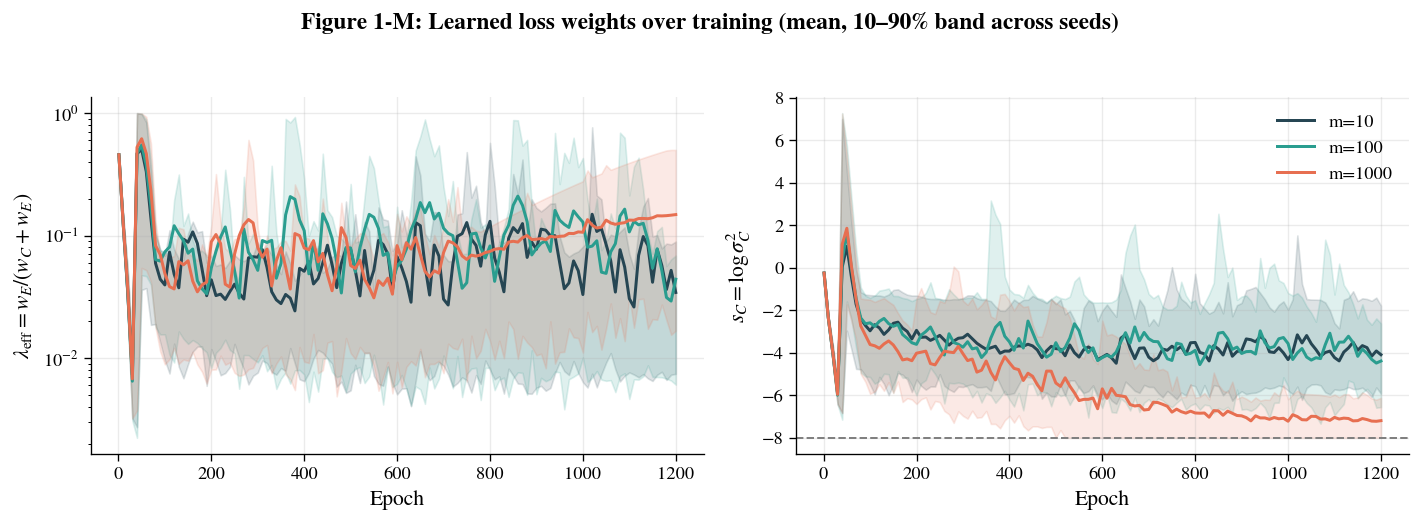

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for m in CAPACITIES:
    g = dfT[dfT.m == m].groupby("epoch")
    for ax, key, lab in [(axes[0], "lam_eff", r"$\lambda_{\mathrm{eff}}=w_E/(w_C+w_E)$"),
                          (axes[1], "s_C", r"$s_C=\log\sigma_C^2$")]:
        mu, lo, hi = g[key].mean(), g[key].quantile(0.1), g[key].quantile(0.9)
        ax.plot(mu.index, mu.values, color=PALETTE_CAPACITY[m], lw=1.8, label=f"m={m}")
        ax.fill_between(mu.index, lo.values, hi.values, color=PALETTE_CAPACITY[m], alpha=0.15)
        ax.set_xlabel("Epoch", labelpad=4)
        ax.set_ylabel(lab, labelpad=5)
axes[0].set_yscale("log")
axes[1].legend(frameon=False, loc="best")
axes[1].axhline(S_CLIP[0], color="gray", ls="--", lw=1.2)

fig.suptitle("Figure 1-M: Learned loss weights over training (mean, 10–90% band across seeds)", y=1.03)
for ax in axes.flat:
    ax.tick_params(axis="both", which="major", length=4, width=0.8)
fig.tight_layout()
fig.savefig(os.path.join(RESULTS_DIR, "Figure_1M.pdf"), format="pdf", bbox_inches="tight")
plt.show()

## Summary

The final cell prints the tables and significance results from all four ablations and saves the text summary under `Track1_07_Results/summary.txt`. The results should be interpreted alongside Chapter 4's discussion of the effective step-size change induced by the convex-combination objective

In [21]:
import io, contextlib
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    print(f"=== Track 1 / notebook 07 summary | seeds={len(SEED_LIST)} n_test={N_TEST} "
          f"val_criterion={VAL_CRITERION} smoke={SMOKE_TEST} ===\n")
    print("--- Table 1-E: step-size-matched control ---"); print(table_1e.to_string())
    print("\n--- Part A significance (e2e vs step-matched CE) ---"); print(sig_A.to_string(index=False))
    print("\n--- Table 1-F: additive penalty (lr=0.5) ---"); print(table_1f.to_string())
    print(f"non-finite runs: {int((~dfB.finite).sum())}")
    print("\n--- Part B significance (beta vs beta=0) ---"); print(sig_B.to_string(index=False))
    print("\n--- Table 1-G: validation-based pipelines ---"); print(table_1g.to_string())
    print("\n--- Part C significance ---"); print(sig_C.to_string(index=False))
    print("\n--- Part C selected lambda counts ---")
    print(dfS.pivot_table(index="m", columns="lam_hat", values="seed", aggfunc="count", fill_value=0).to_string())
    print("\n--- Part C selected early-stopping epoch ---")
    print(dfS.groupby("m")["t_hat"].describe()[["mean", "std", "min", "50%", "max"]].round(1).to_string())
    print("\n--- Table 1-H: uncertainty weighting ---"); print(table_1h.to_string())
    print(f"non-finite: {int((~dfD.finite).sum())}, runs hitting clip: {int((dfD.clip_hits > 0).sum())}/{len(dfD)}")
    print("\n--- Part D significance ---"); print(sig_D.to_string(index=False))
text = buf.getvalue()
with open(os.path.join(RESULTS_DIR, "summary.txt"), "w") as f:
    f.write(text)
print(text)

=== Track 1 / notebook 07 summary | seeds=30 n_test=50000 val_criterion=brier smoke=False ===

--- Table 1-E: step-size-matched control ---
                                    mse_eta              ece            brier        brier_cal        brier_ref          test_ce
m    condition                                                                                                                  
10   baseline (lr=0.5)      0.0189 ± 0.0078  0.0694 ± 0.0195  0.1663 ± 0.0077  0.0090 ± 0.0039  0.1573 ± 0.0053  0.5512 ± 0.0424
     e2e lam=0.05 (lr=0.5)  0.0097 ± 0.0054  0.0453 ± 0.0184  0.1574 ± 0.0054  0.0050 ± 0.0037  0.1524 ± 0.0031  0.4963 ± 0.0173
     CE ctrl (lr=0.025)     0.0131 ± 0.0045  0.0644 ± 0.0263  0.1606 ± 0.0044  0.0083 ± 0.0040  0.1523 ± 0.0019  0.5010 ± 0.0112
     e2e lam=0.1 (lr=0.5)   0.0101 ± 0.0054  0.0459 ± 0.0179  0.1577 ± 0.0054  0.0051 ± 0.0038  0.1525 ± 0.0029  0.4981 ± 0.0170
     CE ctrl (lr=0.05)      0.0100 ± 0.0047  0.0447 ± 0.0171  0.1575 ± 0.0047  0.0052 